# OpenFace-3.0: feature extractor evaluation

Run with the **OpenFace-3.0** kernel (env in `envs/OpenFace-3.0/`).

There is no ground truth yet, so section 5 checks coverage, plausibility, and stability instead of accuracy. The current test set is 7 still images (one-frame clips); the real test set will be videos from several camera angles.

In [1]:
import contextlib
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src import clip_io, plots, schema

ROOT = clip_io.REPO_ROOT
MODEL = 'OpenFace-3.0'
MODEL_DIR = ROOT / 'models' / MODEL
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DEVICE

'cuda'

## 1. Model card

| Field | Value |
|---|---|
| Paper | Hu, Mathur, Liang, Morency. *OpenFace 3.0: A Lightweight Multitask System for Comprehensive Facial Behavior Analysis.* arXiv:2506.02891 (FG 2025) |
| Repo URL | https://github.com/CMU-MultiComp-Lab/OpenFace-3.0 |
| Commit hash | `662a555a8566ae3aec8139cb8c72acf6d06e0eb3` (2025-06-10) |
| Inference code | PyPI `openface-test==0.1.26` (bundles RetinaFace + STAR; not tied to a repo commit) |
| Code license | OpenFace 3.0 license: academic or non-profit, **non-commercial research use only** |
| Weights | `models/OpenFace-3.0/weights/`, identical to Hugging Face `nutPace/openface_weights`. SHA-256: `Alignment_RetinaFace.pth` 2979b33f…, `MTL_backbone.pth` 72f45843…, `mobilenetV1X0.25_pretrain.tar` 75c37f8d… |
| Weights license | **Not stated** (no license or model card on Hugging Face) |
| Pipeline | RetinaFace MobileNet-0.25 detection → crop of the top-scoring box (not aligned) → EfficientNet-B0 multitask model (gaze, AU, emotion) |
| Inputs required | BGR face crop; the package converts to RGB, resizes to 224×224, ImageNet-normalizes |
| Outputs | Gaze yaw/pitch; 8 unnamed AU scores; 8 emotion logits; face confidence. **No head pose** (paper; issue #6) |
| Native units / conventions | Gaze in radians (inferred from training code's `cos()`/`sin()`; paper doesn't state), sign directions undocumented. AU scores in [−1, 1], trained on DISFA as present/absent (intensity ≥ 2, threshold 0.5); which AU each is is undocumented (issues #1, #9). Emotion: 8 AffectNet classes, order disputed (README vs issue #15) |
| Conversion to schema | `gaze_yaw_deg`, `gaze_pitch_deg` = radians × 180/π, **signs not yet verified** (no flip applied). AU scores → `extra_au_raw_0..7` only, no `AUNN_*` columns. Emotion logits → `extra_emotion_logit_0..7`. Top detection score → `face_conf` (0 when below the package's 0.5 threshold). Box → `extra_bbox_*` |
| Env | `envs/OpenFace-3.0/` (pyproject.toml + uv.lock), kernel `OpenFace-3.0`: Python 3.11.17, torch 2.14.1+cu126 |

In [2]:
!git -C {MODEL_DIR} remote get-url origin
!git -C {MODEL_DIR} rev-parse HEAD

git@github.com:CMU-MultiComp-Lab/OpenFace-3.0.git
662a555a8566ae3aec8139cb8c72acf6d06e0eb3


## 2. Setup log

Ubuntu, uv 0.13.0, Python 3.11.17, torch 2.14.1+cu126 (CUDA runtime 12.6), driver 580.178.04, RTX 2080 SUPER 8 GB.

| # | Step / command | Result | Error | Fix |
|---|---|---|---|---|
| 1 | Inspect repo | Python must be 3.10–3.11 (pins); torch unpinned; weights present and match Hugging Face | README's two install steps conflict (numpy 2.2.3 vs 1.26.4, opencv 4.9 vs 4.11, scipy 1.15.2 vs 1.13) | Install only `openface-test==0.1.26`; the clone's `requirements.txt` is for training scripts that can't run unedited |
| 2 | `uv init --bare --python 3.11` | Project created | uv auto-added it to a workspace via the root `pyproject.toml` (one shared lockfile) | Removed workspace section; re-ran with `--no-workspace`; `uv python pin 3.11` |
| 3 | PyTorch cu126 index (explicit) | Config OK | none | cu126 for sm_75 (RTX 2080 SUPER); driver supports up to CUDA 13.0 |
| 4 | `uv add openface-test==0.1.26 torch torchvision`; `uv add --editable ../..` | numpy 1.26.4, opencv 4.11.0.86 (both packages), pandas 2.2.3, pyarrow 26.0.0 | none | `dlib` not installed (only needed for landmarks, not used) |
| 5 | `uv add --dev ipykernel`; register kernel `OpenFace-3.0` | Kernel registered | none | |
| 6 | Verify on repo's `images/0.jpg`, `images/test.avi` | CUDA OK; models load; inference OK; ~58 img/s on a 224×224 image | `FileNotFoundError: ./weights/mobilenetV1X0.25_pretrain.tar` | Path hard-coded relative to the working directory; models are built inside `models/OpenFace-3.0/` (see section 3) |
| 6b | Video decode check | 434 frames (header says 870) | Last 2 frames had no timestamp; OpenCV reported 0.0 | `src/clip_io.iter_frames` fills them from the previous interval and warns |
| 7 | First notebook run: save to parquet | Inference OK on all 7 test images | `ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4` (pyarrow 26.0.0; its wheels declare no numpy dependency, so uv couldn't catch it) | Tested 21–26 against numpy 1.26.4 + pandas 2.2.3: 26 needs NumPy 2, 21–22 crash on exit, 23–25 work. Added `pyarrow<26` to this env only → 25.0.1 |

## 3. Run on test clips

Two workarounds for the package, without editing `models/`:
- RetinaFace's constructor loads `./weights/mobilenetV1X0.25_pretrain.tar` relative to the working directory, so the models are built inside `models/OpenFace-3.0/`.
- `FaceDetector` only accepts an image **file path** (the package's own `process_video` passes it frames and would crash). `ArrayFaceDetector` overrides just the image-loading method to accept an in-memory BGR frame; the detection code itself is unchanged.

Like the package's `get_face`, only the top-scoring face is used, and only if its score is ≥ 0.5. Unlike the package, the crop box is clamped to the image.

In [3]:
from openface.face_detection import FaceDetector
from openface.multitask_model import MultitaskPredictor


class ArrayFaceDetector(FaceDetector):
    """FaceDetector that takes a BGR image array instead of a file path."""

    def preprocess_image(self, image, resize: float = 1.0):
        # Same steps as FaceDetector.preprocess_image, minus cv2.imread
        img_raw = image
        img = np.float32(img_raw)
        if resize != 1:
            img = cv2.resize(img, None, fx=resize, fy=resize, interpolation=cv2.INTER_LINEAR)
        img -= (104, 117, 123)
        img = img.transpose(2, 0, 1)
        img = torch.from_numpy(img).unsqueeze(0).to(self.device)
        return img, img_raw


with contextlib.chdir(MODEL_DIR):  # package loads ./weights/... relative to cwd
    detector = ArrayFaceDetector('./weights/Alignment_RetinaFace.pth', device=DEVICE)
    multitask = MultitaskPredictor('./weights/MTL_backbone.pth', device=DEVICE)

/home/ciber/Desktop/extractor-eval/envs/OpenFace-3.0/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ciber/Desktop/extractor-eval/envs/OpenFace-3.0/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Loading pretrained model from ./weights/Alignment_RetinaFace.pth
remove prefix 'module.'
Missing keys:0
Unused checkpoint keys:0
Used keys:300


/home/ciber/Desktop/extractor-eval/envs/OpenFace-3.0/.venv/lib/python3.11/site-packages/timm/models/_factory.py:126: UserWarning: Mapping deprecated model name tf_efficientnet_b0_ns to current tf_efficientnet_b0.ns_jft_in1k.
  model = create_fn(


Loading multitask model from ./weights/MTL_backbone.pth...


In [4]:
VIS_THRESHOLD = detector.vis_threshold  # 0.5, the package default
N_AU, N_EMOTION = 8, 8

OUTPUT_COLUMNS = (
    ['gaze_yaw_deg', 'gaze_pitch_deg']
    + [f'extra_au_raw_{i}' for i in range(N_AU)]
    + [f'extra_emotion_logit_{i}' for i in range(N_EMOTION)]
    + ['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']
)


def predict(image):
    """Run OpenFace 3.0 on one BGR frame. Returns (face_conf, outputs or None)."""
    dets, _ = detector.detect_faces(image)
    if dets is None or len(dets) == 0:
        return 0.0, None
    top = dets[np.argmax(dets[:, 4])]
    face_conf = float(top[4])
    if face_conf < VIS_THRESHOLD:
        return face_conf, None

    h, w = image.shape[:2]
    x1, y1 = max(int(top[0]), 0), max(int(top[1]), 0)
    x2, y2 = min(int(top[2]), w), min(int(top[3]), h)
    if x2 <= x1 or y2 <= y1:
        return face_conf, None

    emotion, gaze, au = multitask.predict(image[y1:y2, x1:x2])
    gaze = gaze[0].cpu().numpy()
    outputs = {
        # radians -> degrees; sign convention not yet verified against the schema
        'gaze_yaw_deg': float(np.degrees(gaze[0])),
        'gaze_pitch_deg': float(np.degrees(gaze[1])),
        'extra_bbox_x1': x1, 'extra_bbox_y1': y1, 'extra_bbox_x2': x2, 'extra_bbox_y2': y2,
    }
    outputs.update({f'extra_au_raw_{i}': float(v) for i, v in enumerate(au[0].cpu().numpy())})
    outputs.update({f'extra_emotion_logit_{i}': float(v) for i, v in enumerate(emotion[0].cpu().numpy())})
    return face_conf, outputs

In [5]:
manifest = clip_io.load_manifest()
manifest

,clip_id,video_path,camera,expected_emotion
0,front,test_pictures/front.jpeg,front,neutral
1,below,test_pictures/below.jpeg,below,neutral
2,neutral,test_pictures/neutral.jpeg,front,neutral
3,happy,test_pictures/happy.jpeg,front,happy
4,sad,test_pictures/sad.jpeg,front,sad
5,angry,test_pictures/angry.jpeg,front,angry
6,surprised,test_pictures/surprised.jpeg,front,surprised


In [6]:
results, timings = {}, {}
for row in manifest.itertuples():
    records = []
    t0 = time.perf_counter()
    for frame, timestamp_ms, image in clip_io.iter_frames(clip_io.clip_path(row)):
        face_conf, outputs = predict(image)
        record = {'clip_id': row.clip_id, 'frame': frame, 'timestamp_ms': timestamp_ms,
                  'face_conf': float(face_conf) if outputs is not None else 0.0}
        record.update(outputs or {})
        records.append(record)
    timings[row.clip_id] = time.perf_counter() - t0
    results[row.clip_id] = pd.DataFrame.from_records(records, columns=list(schema.REQUIRED_COLUMNS) + OUTPUT_COLUMNS)
    print(f'{row.clip_id}: {len(records)} frames in {timings[row.clip_id]:.1f} s')

front: 1 frames in 0.4 s
below: 1 frames in 0.1 s
neutral: 1 frames in 0.1 s
happy: 1 frames in 0.1 s
sad: 1 frames in 0.1 s
angry: 1 frames in 0.1 s
surprised: 1 frames in 0.1 s


## 4. Save output in the common schema

`save_output` runs `schema.validate` and refuses to write a file that fails it. Fix the conversion in `predict`, not the check.

In [7]:
for clip_id, df in results.items():
    df = df.astype({'frame': 'int64', 'timestamp_ms': 'float64', 'face_conf': 'float64'})
    out_cols = [c for c in df.columns if c not in schema.REQUIRED_COLUMNS and not c.startswith(schema.EXTRA_PREFIX)]
    df[out_cols] = df[out_cols].astype('float64')
    df = schema.add_missing_au_pairs(df)
    print(clip_io.save_output(df, MODEL, clip_id))

/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/front.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/below.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/neutral.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/happy.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/sad.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/angry.parquet
/home/ciber/Desktop/extractor-eval/outputs/OpenFace-3.0/surprised.parquet


## 5. Quick checks

These read back the saved files, so they test exactly what was written.

In [8]:
out = clip_io.load_outputs(MODEL)
print('output columns:', schema.output_columns(out))

output columns: ['gaze_yaw_deg', 'gaze_pitch_deg']


### Face-detection rate

,detection_rate
clip_id,
angry,1.0
below,1.0
front,1.0
happy,1.0
neutral,1.0
sad,1.0
surprised,1.0


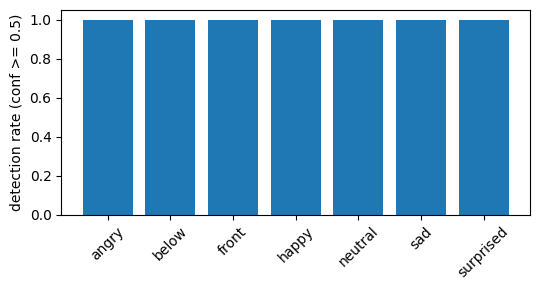

In [9]:
display(plots.detection_rate(out).to_frame())
plots.plot_detection_rate(out);

### Speed (fps on this machine)

Includes video decoding. Note the hardware (CPU/GPU) in the verdict.

In [10]:
plots.fps_table(timings, out)

,n_frames,seconds,fps
angry,1,0.097065,10.302350
below,1,0.087835,11.384949
front,1,0.414617,2.411867
happy,1,0.068860,14.522312
neutral,1,0.076173,13.128047
sad,1,0.067589,14.795306
surprised,1,0.069406,14.407953


### Per-clip summary

One row per clip with mean outputs over detected frames. Emotion is shown under both orders in circulation: the README's and the one proposed in issue #15 (Anger and Disgust swapped). `expected_emotion` from the manifest shows which order fits better.

In [11]:
EMOTIONS_README = ['Neutral', 'Happy', 'Sad', 'Surprise', 'Fear', 'Disgust', 'Anger', 'Contempt']
EMOTIONS_ISSUE15 = ['Neutral', 'Happy', 'Sad', 'Surprise', 'Fear', 'Anger', 'Disgust', 'Contempt']
logit_cols = [f'extra_emotion_logit_{i}' for i in range(N_EMOTION)]

detected = out[out['face_conf'] >= VIS_THRESHOLD]
summary = detected.groupby('clip_id').agg(
    n_frames=('frame', 'size'), face_conf=('face_conf', 'mean'),
    gaze_yaw_deg=('gaze_yaw_deg', 'mean'), gaze_pitch_deg=('gaze_pitch_deg', 'mean'),
)
top_emotion = detected.groupby('clip_id')[logit_cols].mean().to_numpy().argmax(axis=1)
summary['emotion_readme'] = [EMOTIONS_README[i] for i in top_emotion]
summary['emotion_issue15'] = [EMOTIONS_ISSUE15[i] for i in top_emotion]
summary = manifest.set_index('clip_id').drop(columns='video_path').join(summary, how='left')
summary.round(2)

,camera,expected_emotion,n_frames,face_conf,gaze_yaw_deg,gaze_pitch_deg,emotion_readme,emotion_issue15
clip_id,,,,,,,,
front,front,neutral,1,1.0,-5.06,6.65,Surprise,Surprise
below,below,neutral,1,1.0,1.71,-1.88,Neutral,Neutral
neutral,front,neutral,1,1.0,-7.78,8.28,Neutral,Neutral
happy,front,happy,1,1.0,-8.99,11.21,Happy,Happy
sad,front,sad,1,1.0,-4.43,7.62,Sad,Sad
angry,front,angry,1,1.0,-9.55,3.21,Anger,Disgust
surprised,front,surprised,1,1.0,-4.61,2.55,Surprise,Surprise


In [12]:
au_raw_cols = [f'extra_au_raw_{i}' for i in range(N_AU)]
detected.groupby('clip_id')[au_raw_cols].mean().round(3).style.background_gradient(axis=None, vmin=-1, vmax=1)

,extra_au_raw_0,extra_au_raw_1,extra_au_raw_2,extra_au_raw_3,extra_au_raw_4,extra_au_raw_5,extra_au_raw_6,extra_au_raw_7
clip_id,,,,,,,,
angry,0.001000,0.000000,0.996000,0.009000,0.007000,0.001000,0.219000,0.045000
below,0.006000,0.001000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000
front,0.014000,0.042000,0.000000,0.000000,0.000000,0.000000,0.242000,0.025000
happy,0.005000,0.000000,0.000000,0.173000,0.000000,0.998000,0.993000,0.017000
neutral,0.056000,0.180000,0.000000,0.000000,0.000000,0.000000,0.093000,0.007000
sad,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
surprised,0.433000,0.827000,0.000000,0.000000,0.000000,0.000000,0.744000,0.021000


### Detections on single-image clips

Top face box and confidence drawn on each image.

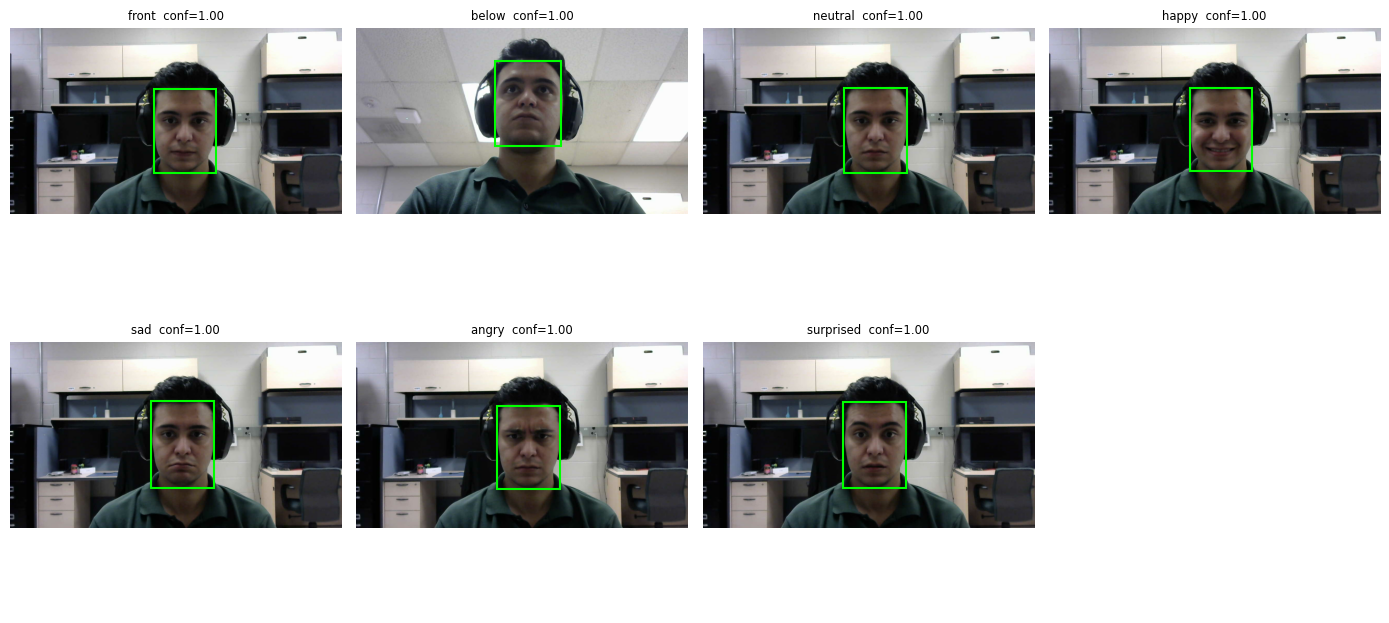

In [13]:
still = [r for r in manifest.itertuples() if clip_io.is_image(clip_io.clip_path(r))]
if still:
    ncols = 4
    fig, axes = plt.subplots(-(-len(still) // ncols), ncols, figsize=(3.5 * ncols, 3.5 * -(-len(still) // ncols)), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, row in zip(axes.flat, still):
        _, _, img = next(clip_io.iter_frames(clip_io.clip_path(row), rgb=True))
        r = out[out['clip_id'] == row.clip_id].iloc[0]
        ax.imshow(img)
        if r['face_conf'] >= VIS_THRESHOLD:
            x1, y1, x2, y2 = r[['extra_bbox_x1', 'extra_bbox_y1', 'extra_bbox_x2', 'extra_bbox_y2']]
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color='lime', lw=1.5))
        ax.set_title(f"{row.clip_id}  conf={r['face_conf']:.2f}", fontsize='small')
    plt.tight_layout()
    plt.show()

### Standard plots per clip

Video clips only (time series need more than one frame).

In [14]:
for clip_id, df in out.groupby('clip_id'):
    if len(df) < 2:
        continue
    plots.plot_face_conf(df)
    plots.plot_gaze(df)
    plt.show()

### Plausibility and stability (no ground truth)

- Value ranges: do angles and AU levels look reasonable for what happens in each clip?
- Jitter: median absolute frame-to-frame change on detected frames. A high value on a still face means a noisy model.
- AU occurrence rate: AUs that are always on or always off are suspicious.

In [15]:
angle_cols = [c for c in schema.GAZE_COLUMNS if c in out]
display(detected[angle_cols + au_raw_cols].describe().T.round(3))

# Jitter needs consecutive frames, so only video clips count
multi = detected.groupby('clip_id').filter(lambda d: len(d) > 1)
if len(multi):
    jitter = multi.groupby('clip_id')[angle_cols].apply(lambda d: d.diff().abs().median())
    display(jitter.rename(columns=lambda c: c.replace('_deg', '_jitter_deg')))
else:
    print('no multi-frame clips yet: jitter skipped')

,count,mean,std,min,25%,50%,75%,max
gaze_yaw_deg,7.0,-5.529,3.828,-9.550,-8.385,-5.061,-4.516,1.710
gaze_pitch_deg,7.0,5.374,4.367,-1.883,2.878,6.647,7.947,11.207
extra_au_raw_0,7.0,0.074,0.160,0.000,0.003,0.006,0.035,0.433
extra_au_raw_1,7.0,0.150,0.306,0.000,0.000,0.001,0.111,0.827
extra_au_raw_2,7.0,0.142,0.377,0.000,0.000,0.000,0.000,0.996
extra_au_raw_3,7.0,0.026,0.065,0.000,0.000,0.000,0.005,0.173
extra_au_raw_4,7.0,0.001,0.003,0.000,0.000,0.000,0.000,0.007
extra_au_raw_5,7.0,0.143,0.377,0.000,0.000,0.000,0.001,0.998
extra_au_raw_6,7.0,0.327,0.388,0.000,0.046,0.219,0.493,0.993
extra_au_raw_7,7.0,0.018,0.015,0.000,0.008,0.017,0.023,0.045


no multi-frame clips yet: jitter skipped


### Failure cases

Frames where the face was missed or detected with low confidence. Look at a few to see why (pose, occlusion, lighting, blur).

In [16]:
failures = plots.failure_frames(out)
display(failures.groupby('clip_id').size().rename('n_failures').to_frame())
failures.head(20)

,n_failures
clip_id,


,clip_id,frame,timestamp_ms,face_conf


In [17]:
def show_frames(clip_id, frames, ncols=4):
    row = manifest.set_index('clip_id').loc[clip_id]
    wanted = set(frames)
    images = [(f, img) for f, _, img in clip_io.iter_frames(clip_io.DATA_DIR / row.video_path, rgb=True) if f in wanted]
    if not images:
        return
    nrows = -(-len(images) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.5 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (f, img) in zip(axes.flat, images):
        ax.imshow(img)
        ax.set_title(f'{clip_id} frame {f}', fontsize='small')
    plt.show()

# Up to 8 evenly spaced failure frames per clip
for clip_id, f in failures.groupby('clip_id'):
    show_frames(clip_id, f['frame'].iloc[np.linspace(0, len(f) - 1, min(8, len(f))).astype(int)])

## 6. Notes and verdict

**Hardware used for the speed numbers:** RTX 2080 SUPER 8 GB, CUDA 12.6

**Known from setup (before running on test data):**
- No head pose output.
- AU outputs are 8 unnamed occurrence scores, not intensities; the AU mapping is undocumented. Others report weak AU signal (issue #9).
- Gaze sign conventions are unverified.
- Weights license not stated; code license is non-commercial research only.
- Face crop is not aligned before the multitask model.

**Strengths:**

**Weaknesses:**

**Verdict:** keep / drop

**Why:**